# 02. Sampling preview

**What you will achieve:** Preview the allowed perturbation extremes **without drawing random samples**. The preview method may return two or four spectra, depending on which perturbations are active. Preview spectra are intentionally not guaranteed to be area-normalized; do not feed them to ACE production as if they were validated stochastic samples.

**For your own data:** replace `INPUT_FILE` first; then change the brief settings cell as needed. This notebook uses `tests/fixtures/input_2.leapr` and the real TARA Core interfaces. There is no backend execution here.


## What a preview tells you

A preview is a **deterministic stress test of the configured perturbation bounds**, not a probability distribution. With both shift and amplitude variation active, TARA combines the positive and negative extremes; turning one perturbation limit to zero removes the corresponding combinations.

The preview mode sets `n_samples=0`; a configuration warning is expected because no stochastic ensemble will be generated. A separate warning may indicate that preview spectra have not been normalized to unit area. This is intentional for inspecting extreme amplitude changes.

**Interpretation:** compare the number of returned extrema, their dominant peak locations, and their areas. Do not call them random realizations or infer error bars from them.


## 1. Locate TARA

The next cell finds TARA and imports the sampling APIs.

In [1]:
# Locate the TARA repository so this notebook works from any of its subdirectories.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if
     (p / 'core' / 'config.py').is_file() and
     (p / 'core' / 'sampler' / 'concrete_samplers.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter inside your TARA repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from core.config import TaraConfig
from core.data.input_pdos import PhononSpectra
from core.sampler.concrete_samplers import TaraSampler
from input_output.factory import load_file_object

print(f'TARA root: {PROJECT_ROOT}')


TARA root: /home/aitor/postdoc/tara_preview_V3_5


## 2. Select the required inputs

**Required settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `INPUT_FILE` | `tests/fixtures/input_2.leapr` | Source of the reference phonon spectrum. |

In [2]:
INPUT_FILE = PROJECT_ROOT / 'tests' / 'fixtures' / 'input_2.leapr'
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f'Example LEAPR fixture is missing: {INPUT_FILE}')

## 3. Load the graphite reference

Load the selected input and prepare the normalized reference PDOS.

In [4]:
file_template, raw_pdos = load_file_object(filepath=INPUT_FILE)
reference_spectrum = PhononSpectra(
    pdos=raw_pdos,
    auto_normalize=True
)
print(f'Input: {INPUT_FILE.name}')

Input: input_2.leapr


## 4. Set up this experiment

Only the perturbation bounds are relevant: no random spectra are drawn.

**Required settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_ENERGY_SHIFT_MEV` | `1.0` | Maximum phonon-energy displacement in meV. |
| `MAX_AMPLITUDE_SHIFT_PCT` | `5.0` | Maximum relative amplitude change in percent. |

**Fixed settings for this example**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `N_SAMPLES` | `0` | Zero selects a deterministic preview with no stochastic draws. |

In [5]:
MAX_ENERGY_SHIFT_MEV = 1.0
MAX_AMPLITUDE_SHIFT_PCT = 5.0
N_SAMPLES = 0

**Optional settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `AMPLITUDE_METHOD` | `'fast'` | Amplitude perturbation method. |
| `SPATIAL_METHOD` | `'diffeomorphic'` | Energy-grid perturbation method. |

In [6]:
AMPLITUDE_METHOD = 'fast'
SPATIAL_METHOD = 'diffeomorphic'

In [8]:
# Validate all perturbation bounds and sampling strategies using TaraConfig.
configuration = TaraConfig(
    max_energy_shift_mev=MAX_ENERGY_SHIFT_MEV,
    max_amplitude_shift_pct=MAX_AMPLITUDE_SHIFT_PCT,
    n_samples=N_SAMPLES,
)

# Initialize TaraSampler with the selected amplitude and spatial methods.
sampler = TaraSampler(
    config=configuration,
    spectra=reference_spectrum,
    amplitude_method=AMPLITUDE_METHOD,
    spatial_method=SPATIAL_METHOD,
)

/home/aitor/postdoc/tara_preview_V3_5/core/config.py:108: UserWarning: n_samples is set to 0. This configuration is only valid for preview generation.
  warnings.warn("n_samples is set to 0. This configuration is only valid for preview generation.")


## 5. Produce the deterministic preview

`generate_preview()` explores combinations of the permitted perturbation extremes; it is **not** the random ensemble generator. Normalization is deliberately disabled internally for preview spectra, so area changes do not automatically signal an implementation error.

In [9]:
from notebooks.tara_plotting import plot_PDOS
import matplotlib.pyplot as plt

/home/aitor/postdoc/tara_preview_V3_5/core/data/input_pdos.py:67: UserWarning: PhononSpectra auto_normalize=False: This spectrum is NOT normalized to unity. It is physically invalid and should ONLY be used for visual previewing.
  warnings.warn(


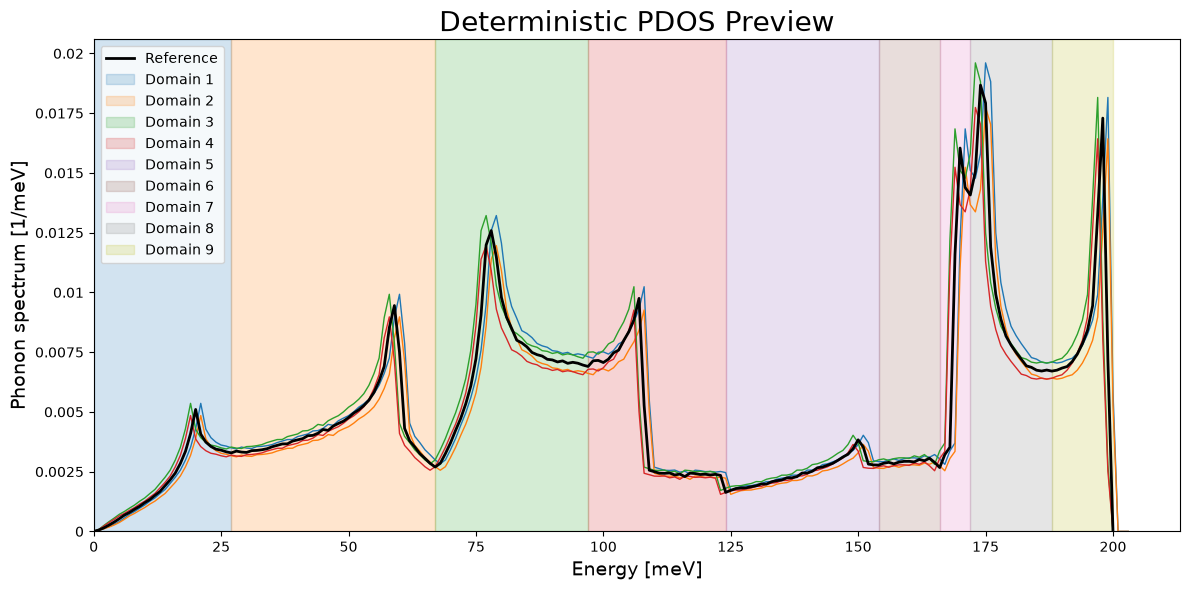

In [10]:
# Generate the deterministic preview ensemble.
preview_spectra = sampler.generate_preview()

# Plot the reference PDOS and all deterministic extrema.
fig, ax = plt.subplots(figsize=(12, 6))

plot_PDOS(
    ax,
    list(preview_spectra),
    preview_spectra.reference,
    title="Deterministic PDOS Preview",
)

# Highlight each perturbation range.
boundaries = preview_spectra.sampling_blocks[0].boundaries
colors = plt.cm.tab10.colors

for i, (start, end) in enumerate(boundaries):
    ax.axvspan(
        start,
        end,
        color=colors[i % len(colors)],
        alpha=0.20,
        label=f"Domain {i + 1}",
    )

ax.legend(loc="best")
plt.tight_layout()
plt.show()

## 6. Zoom into Two Adjacent Perturbation Domains

A full-spectrum PDOS comparison can hide small changes in neighboring peaks. This final plot zooms into **domains 3 and 4** (zero-based `DOMAIN_INDICES = (2, 3)`) **together on one energy axis**, so their relative peak movements and amplitude changes are directly comparable.

The reference PDOS and all generated spectra remain visible. Each selected perturbation domain is shaded separately, and a small margin shows behavior on either side of the two-domain region. Change the indices to inspect another adjacent pair.

**Optional display settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `DOMAIN_INDICES` | `(2, 3)` | Zero-based indices of the third and fourth domains. |
| `ZOOM_MARGIN` | `0.15` | Fraction of the selected energy span added as padding. |

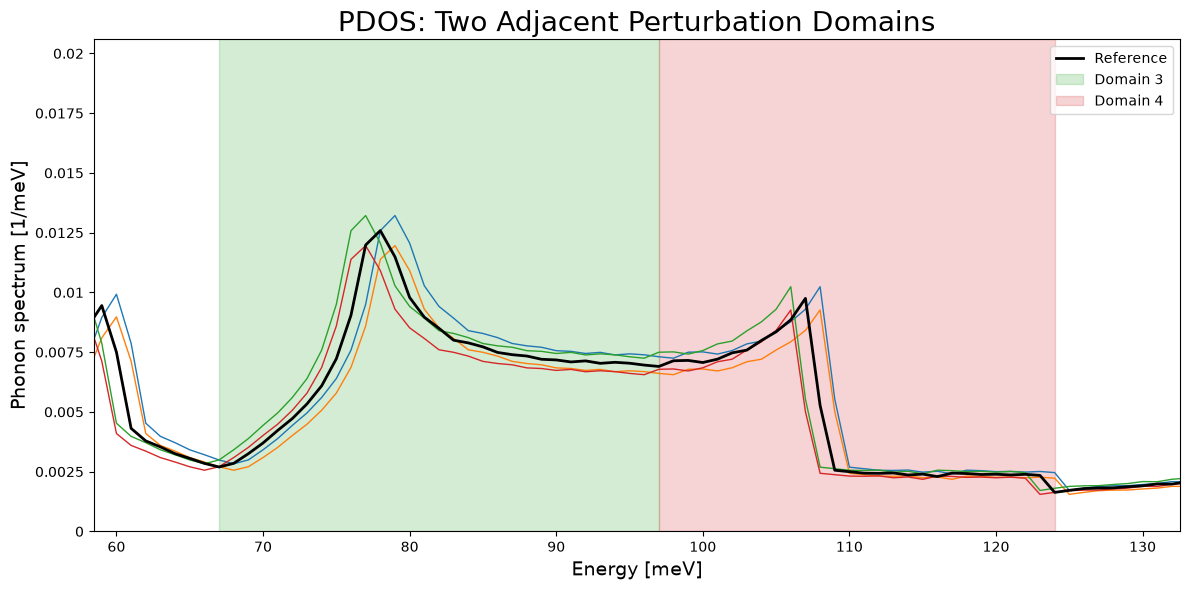

In [11]:
# ---------------------------------------------------------
# Step 6: Zoom into Two Adjacent Perturbation Domains
# ---------------------------------------------------------

DOMAIN_INDICES = (2, 3)  # Zero-based indices: the third and fourth domains.
ZOOM_MARGIN = 0.15

boundaries = preview_spectra.sampling_blocks[0].boundaries

if len(boundaries) <= max(DOMAIN_INDICES):
    raise ValueError(
        f"At least {max(DOMAIN_INDICES) + 1} domains are required; "
        f"the sampler generated {len(boundaries)}."
    )

# Show both adjacent domains on one axis, preserving their relative positions.
start = min(boundaries[i][0] for i in DOMAIN_INDICES)
end = max(boundaries[i][1] for i in DOMAIN_INDICES)
margin = ZOOM_MARGIN * (end - start)

fig, ax = plt.subplots(figsize=(12, 6))

plot_PDOS(
    ax,
    list(preview_spectra),
    preview_spectra.reference,
    title="PDOS: Two Adjacent Perturbation Domains",
)

colors = plt.cm.tab10.colors
for i in DOMAIN_INDICES:
    domain_start, domain_end = boundaries[i]
    ax.axvspan(
        domain_start,
        domain_end,
        color=colors[i % len(colors)],
        alpha=0.20,
        label=f"Domain {i + 1}",
    )

ax.set_xlim(start - margin, end + margin)
ax.legend(loc="best")
plt.tight_layout()
plt.show()